# Resampling

This notebook shows how to run a Resampling pipeline with the same model-loading setup used in `02_models.ipynb`.
The implementation is based on the paper referenced by the ZigZag Diffusion paper:

_Repaint: Inpainting using denoising diffusion probabilistic models. In Proceedings of the IEEE/CVF conference on computer vision and pattern recognition, pp. 11461–11471, 2022._

In [1]:
from zigzag_project.resampling_utils import *
from IPython.display import display
from PIL import Image
OUTPUT_DIR = Path.cwd().parent / "outputs" / "resampling_example"

/home/lenka-hake/Documents/GM/generative-modelling/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:187: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12080). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [2]:
model_name = DREAM_SHARPER

example_prompts = [
    "An elephant in a room full of glassware.",
    # "A dog buying groceries.",
    # "A heart-shaped light blue bomb that explodes inside a pancake."
]

config = get_model_config(model_name)
config

{'model_id': 'Lykon/dreamshaper-xl-v2-turbo',
 'pipeline_type': 'sdxl',
 'num_inference_steps': 4,
 'guidance_scale': 3.5,
 'height': 1024,
 'width': 1024,
 'use_ddim': True}

## Resampling Schedule

Standard diffusion sampling only moves from noisy images to cleaner images (e.g. 20 → 19 → 18), but Resampling sometimes jumps back to a noisier timestep before continuing (e.g. 20 → 19 → 20 → 19 → 20 → 19 → 18). So instead of denoising only once at a timestep, the model can denoise, add noise back, and denoise again. This gives it extra chances to refine the image.

`jump_length` controls how often resampling happens and `jump_n_sample` controls how many total visits happen at that point. For example, `jump_length = 10` and `jump_n_sample = 3` means that every 10 diffusion steps, we revisit that timestep 3 times in total.


In [3]:
resampling_config = get_resampling_config()
example_config = dict(resampling_config, jump_length=10, jump_n_sample=3)
schedule = get_resampling_schedule(config["num_inference_steps"], jump_length=example_config["jump_length"], jump_n_sample=example_config["jump_n_sample"])

print("Default resampling config:", resampling_config, "\n")
print("For this example, we will use the following setup:\n")
print("Resampling config:", example_config)
print("Number of inference steps from the model's config:", config["num_inference_steps"], "(if the number is lower than the jump length, the jump length is clipped)")
print("Schedule length:", len(schedule))
print("Schedule (logical timesteps):", schedule)

Default resampling config: {'jump_length': 10, 'jump_n_sample': 10} 

For this example, we will use the following setup:

Resampling config: {'jump_length': 10, 'jump_n_sample': 3}
Number of inference steps from the model's config: 4 (if the number is lower than the jump length, the jump length is clipped)
Schedule length: 17
Schedule (logical timesteps): [3, 2, 1, 0, 1, 2, 3, 2, 1, 0, 1, 2, 3, 2, 1, 0, -1]


## Re-noising Implementation
The re-noising is implemented using cumulative alpha values. In diffusion, image `x` at timestep `t` is a mix of the clean image and noise, controlled by `alpha_t`:

`x_t = sqrt(alpha_t) * clean_image + sqrt(1 - alpha_t) * noise`

Larger alpha values correspond to cleaner images, while smaller values correspond to noisier ones.  During resampling we move from a cleaner image `x_from` back to a noisier image `x_to` by adding back noise:

`x_to = sqrt(alpha_to / alpha_from) * x_from + sqrt(1 - alpha_to / alpha_from) * noise`


## Resampling Example

In [4]:
pipeline = load_pipeline(model_name)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

In [5]:
run_id = make_run_id()

resampling_paths = generate_images_resampling(
    pipeline,
    example_prompts,
    model_name,
    OUTPUT_DIR,
    seed=42,
    jump_length=example_config["jump_length"],
    jump_n_sample=example_config["jump_n_sample"],
    run_id=run_id
)

resampling_paths

Diffusion steps for prompt 1:   0%|          | 0/16 [00:00<?, ?it/s]

[PosixPath('/home/lenka-hake/Documents/GM/generative-modelling/outputs/resampling_example/dreamshaper-xl-v2-turbo_resampling_000_20260523_232119.png')]

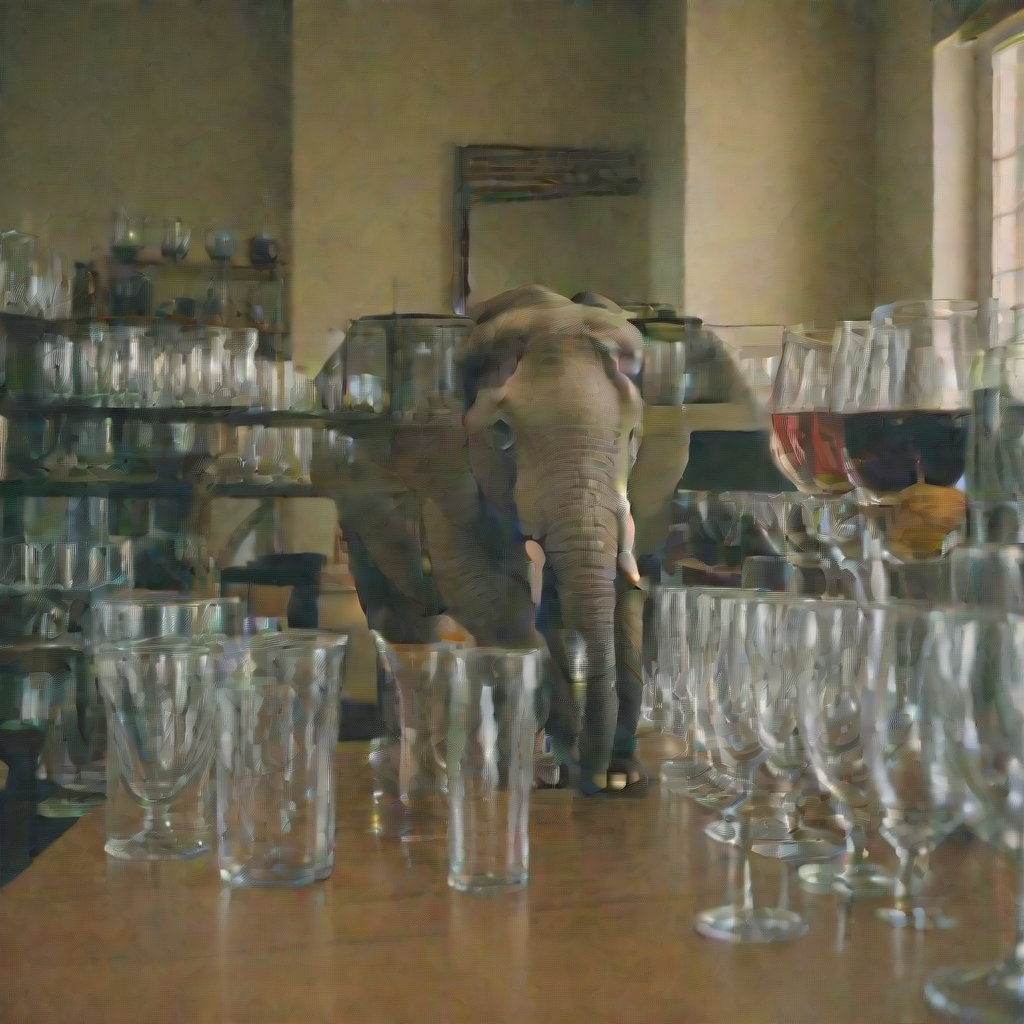

In [6]:
display(Image.open(resampling_paths[0]))